# Clustering Methods Exercises

![Clustering.png](Assets/Clustering.png)

# Цели обучения

- Обсудить алгоритмы обучения без учителя и способы их применения
- Применять кластеризацию
- Применять снижение размерности


## Введение

Для этих упражнений мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические характеристики вина, такие как кислотность, содержание сахара, pH и содержание алкоголя. Он также содержит показатель качества (от 3 до 9, где более высокое значение означает лучшее качество) и цвет (красное или белое). Имя файла — `Wine_Quality_Data`.

Мы будем использовать химические свойства (то есть все, кроме показателя качества и цвета) для кластеризации вин. Хотя это обучение без учителя, может быть интересно посмотреть, как результаты нашей кластеризации соотносятся с цветом и качеством.

In [7]:
from __future__ import print_function
import os
data_path = [  'data']

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit



## Вопрос 1

* Импортируйте данные и проанализируйте характеристики.
* Определите, какие из них являются непрерывными, категориальными и булевыми.
* Сколько записей имеется для двух цветов вина и диапазона показателей качества?
* Постройте гистограмму показателя качества для каждого из цветов вина.

Типы данных для каждой записи. Реализация алгоритма K-means в библиотеке Scikit-learn рассчитана исключительно на работу с непрерывными данными (хотя иногда её применяют и для категориальных или булевых типов). К счастью, все столбцы, которые мы будем использовать (все, кроме «quality» и «color»), являются непрерывными.

In [8]:
# Импорт библиотек и загрузка данных о качестве вина
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath, sep=',')

In [9]:
# Типы данных признаков (непрерывные, категориальные, булевы)
data.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object

In [10]:
# Количество записей для каждого цвета вина и диапазон показателей качества
print(data['color'].value_counts())
print(data['quality'].value_counts().sort_index())

color
white    4898
red      1599
Name: count, dtype: int64
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


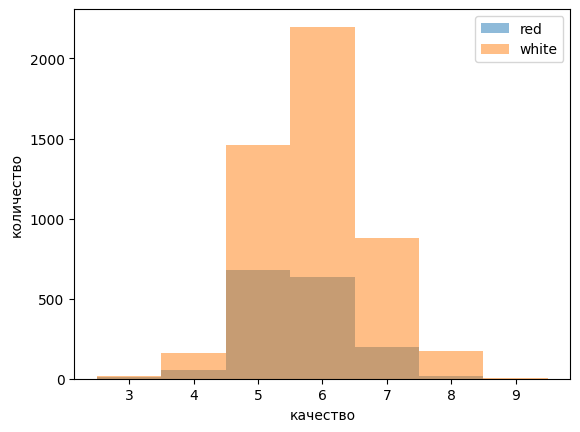

In [11]:
# Гистограмма показателя качества для каждого цвета вина
fig, ax = plt.subplots()
for color, df in data.groupby('color'):
    ax.hist(df['quality'], bins=np.arange(2.5, 10, 1), alpha=0.5, label=color)
ax.set(xlabel='качество', ylabel='количество')
ax.legend()
plt.show()

## Вопрос 2

* Оцените корреляцию и асимметрию соответствующих переменных — всех, кроме цвета и качества.
* Проведите необходимые преобразования признаков и/или масштабирование.
* Проанализируйте парное распределение переменных с помощью парных графиков, чтобы проверить правильность масштабирования и нормализации.


А также анализ значений асимметрии в преддверии преобразований.

In [12]:
# Корреляция признаков (все, кроме цвета и качества)
float_columns = [x for x in data.columns if x not in ['color', 'quality']]
data[float_columns].corr()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
fixed_acidity,1.000000,0.219008,0.324436,-0.111981,0.298195,-0.282735,-0.329054,0.458910,-0.252700,0.299568,-0.095452
volatile_acidity,0.219008,1.000000,-0.377981,-0.196011,0.377124,-0.352557,-0.414476,0.271296,0.261454,0.225984,-0.037640
citric_acid,0.324436,-0.377981,1.000000,0.142451,0.038998,0.133126,0.195242,0.096154,-0.329808,0.056197,-0.010493
residual_sugar,-0.111981,-0.196011,0.142451,1.000000,-0.128940,0.402871,0.495482,0.552517,-0.267320,-0.185927,-0.359415
chlorides,0.298195,0.377124,0.038998,-0.128940,1.000000,-0.195045,-0.279630,0.362615,0.044708,0.395593,-0.256916
free_sulfur_dioxide,-0.282735,-0.352557,0.133126,0.402871,-0.195045,1.000000,0.720934,0.025717,-0.145854,-0.188457,-0.179838
total_sulfur_dioxide,-0.329054,-0.414476,0.195242,0.495482,-0.279630,0.720934,1.000000,0.032395,-0.238413,-0.275727,-0.265740
density,0.458910,0.271296,0.096154,0.552517,0.362615,0.025717,0.032395,1.000000,0.011686,0.259478,-0.686745
pH,-0.252700,0.261454,-0.329808,-0.267320,0.044708,-0.145854,-0.238413,0.011686,1.000000,0.192123,0.121248
sulphates,0.299568,0.225984,0.056197,-0.185927,0.395593,-0.188457,-0.275727,0.259478,0.192123,1.000000,-0.003029


In [13]:
# Асимметрия признаков
skew_columns = data[float_columns].skew().sort_values(ascending=False)
skew_columns

chlorides               5.399828
sulphates               1.797270
fixed_acidity           1.723290
volatile_acidity        1.495097
residual_sugar          1.435404
free_sulfur_dioxide     1.220066
alcohol                 0.565718
density                 0.503602
citric_acid             0.471731
pH                      0.386839
total_sulfur_dioxide   -0.001177
dtype: float64

In [14]:
# Логарифмирование признаков с сильной асимметрией (> 0.75) и масштабирование
for col in skew_columns[skew_columns > 0.75].index:
    data[col] = np.log1p(data[col])

sc = StandardScaler()
data[float_columns] = sc.fit_transform(data[float_columns])

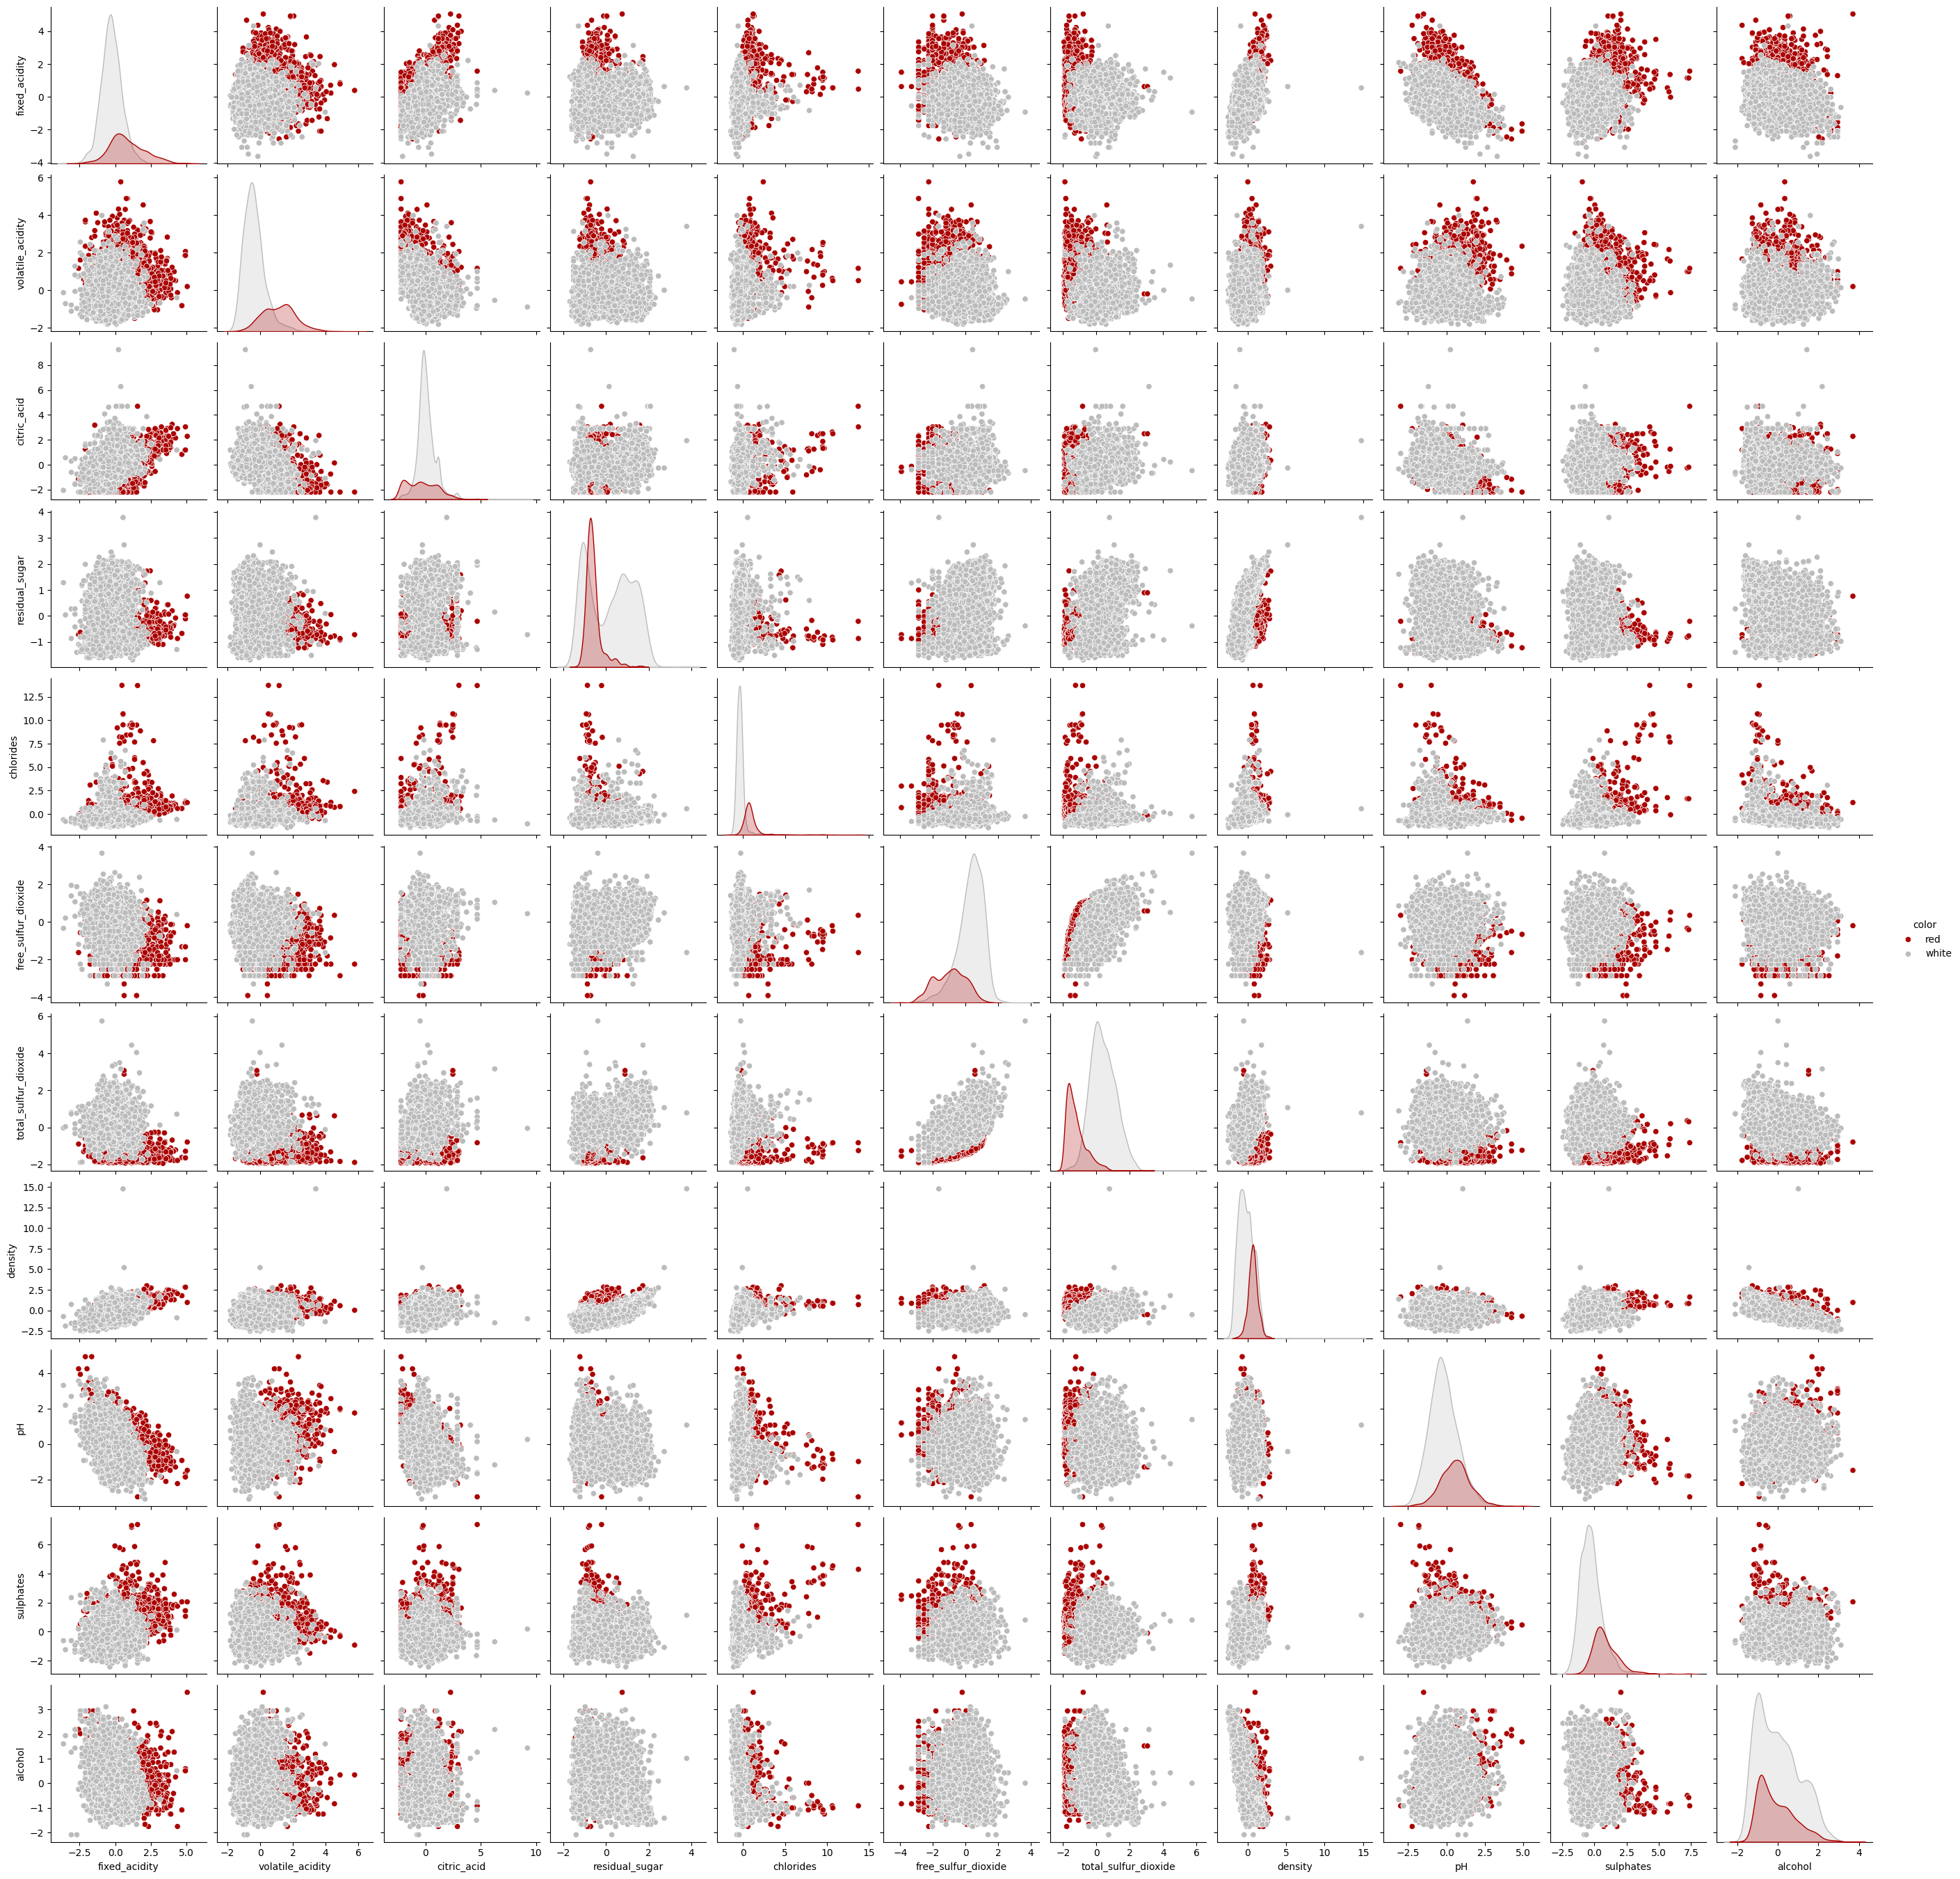

In [15]:
# Парные графики признаков после преобразований
import seaborn as sns
sns.pairplot(data[float_columns + ['color']], hue='color', palette={'white': '#BBBBBB', 'red': '#AA0000'})
plt.show()

## Вопрос 3

* Постройте модель кластеризации методом K-средних с двумя кластерами.
* Проанализируйте кластеры по цвету вина.

In [16]:
# Модель K-средних с двумя кластерами
km = KMeans(n_clusters=2, random_state=42)
data['kmeans'] = km.fit_predict(data[float_columns])

In [17]:
# Распределение вин по кластерам в зависимости от цвета
pd.crosstab(data['kmeans'], data['color'])

color,red,white
kmeans,,
0,1576,87
1,23,4811


## Вопрос 4

* Теперь постройте модели K-Means с количеством кластеров от 1 до 20.
* Для каждой модели запишите количество кластеров и значение инерции.
* Постройте график зависимости количества кластеров от инерции. Можно ли выделить какое-то идеальное количество кластеров?

In [18]:
# Модели K-средних с количеством кластеров от 1 до 20 и их инерция
km_list = []
for clust in range(1, 21):
    km = KMeans(n_clusters=clust, random_state=42)
    km.fit(data[float_columns])
    km_list.append(pd.Series({'clusters': clust, 'inertia': km.inertia_}))

plot_data = pd.concat(km_list, axis=1).T
plot_data

,clusters,inertia
0,1.0,71467.000000
1,2.0,55455.981113
2,3.0,45199.884066
3,4.0,42548.109480
4,5.0,38232.269780
5,6.0,36369.052743
6,7.0,35089.418765
7,8.0,33923.534961
8,9.0,31996.422967
9,10.0,31070.250442


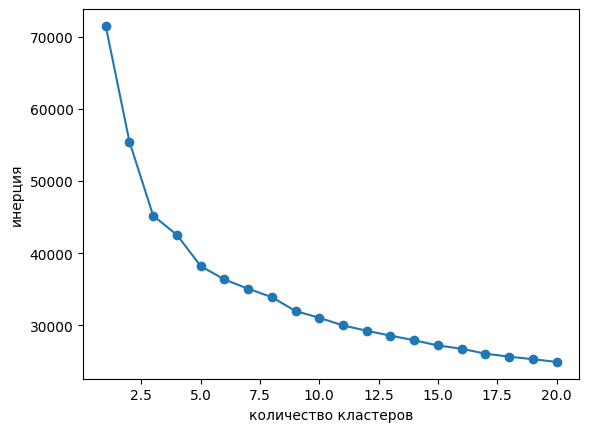

In [19]:
# Зависимость инерции от количества кластеров
ax = plot_data.plot('clusters', 'inertia', marker='o', legend=False)
ax.set(xlabel='количество кластеров', ylabel='инерция')
plt.show()

*Ответ:* инерция плавно уменьшается, и чёткого «локтя» нет, поэтому идеальное количество кластеров однозначно не выделяется. Небольшой изгиб обычно виден в районе 3–5 кластеров.

## Вопрос 5

* Постройте модель агломеративного кластеризации с двумя кластерами.
* Сравните полученные результаты с результатами, полученными с помощью алгоритма K-средних, с точки зрения цвета вина.
* Визуализируйте дендрограмму, построенную с помощью агломеративного кластеризации. *Подсказка:* В SciPy есть модуль [`cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html#module-scipy.cluster.hierarchy), содержащий функции `linkage` и `dendrogram`, необходимые для построения карты связей и отображения полученной дендрограммы.

Обратите внимание, что распределение по кластерам является произвольным: номера основных кластеров для красного и белого цветов могут не совпадать с приведёнными ниже, а также могут различаться при использовании метода K-средних и агломеративного кластерирования.

In [20]:
# Модель агломеративной кластеризации с двумя кластерами
ag = AgglomerativeClustering(n_clusters=2, linkage='ward')
data['agglom'] = ag.fit_predict(data[float_columns])

In [21]:
# Сравнение агломеративной кластеризации и K-средних по цвету вина
pd.crosstab([data['color'], data['agglom']], data['kmeans'])

kmeans           0     1
color agglom            
red   0         13    18
      1       1563     5
white 0         38  4717
      1         49    94

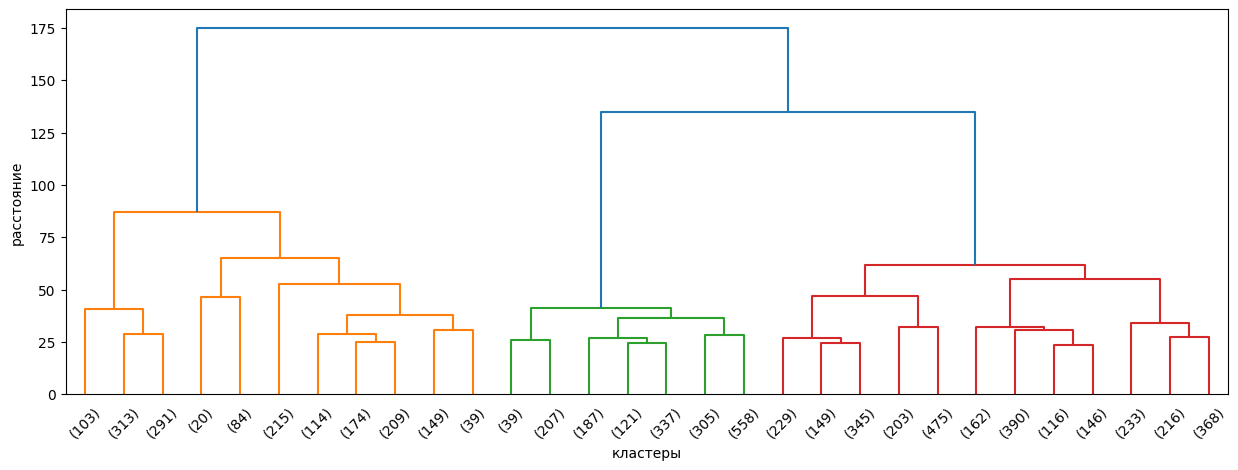

In [22]:
# Дендрограмма агломеративной кластеризации
from scipy.cluster import hierarchy

Z = hierarchy.linkage(data[float_columns], method='ward')
fig, ax = plt.subplots(figsize=(15, 5))
hierarchy.dendrogram(Z, truncate_mode='lastp', p=30, ax=ax)
ax.set(xlabel='кластеры', ylabel='расстояние')
plt.show()

## Вопрос 6

В этом вопросе мы рассмотрим кластеризацию как один из способов инженерии признаков.

* Создайте **бинарную** целевую переменную `y`, указывающую, превышает ли показатель качества значение 7 или нет.
* Создайте переменную `X_with_kmeans` на основе набора данных `data`, удалив из него столбцы «quality», «color» и «agglom». Создайте из него `X_without_kmeans`, удалив столбец «kmeans».
* Для обоих наборов данных с помощью `StratifiedShuffleSplit` с 10 разбиениями обучите 10 классификаторов Random Forest и вычислите среднее значение показателей ROC-AUC.
* Сравните средние значения показателей ROC-AUC для моделей, использующих кластеры k-средних в качестве признака, и для модели, которая их не использует.

In [23]:
# Целевая переменная и наборы признаков с кластерами K-средних и без них
y = (data['quality'] > 7).astype(int)
X_with_kmeans = data.drop(['quality', 'color', 'agglom'], axis=1)
X_without_kmeans = X_with_kmeans.drop('kmeans', axis=1)

In [24]:
# Функция для вычисления среднего ROC-AUC по 10 разбиениям StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=10, random_state=6532)

def get_avg_roc_10splits(estimator, X, y):
    roc_auc_list = []
    for train_index, test_index in sss.split(X, y):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]
        estimator.fit(X_train, y_train)
        y_scored = estimator.predict_proba(X_test)[:, 1]
        roc_auc_list.append(roc_auc_score(y_test, y_scored))
    return np.mean(roc_auc_list)

In [25]:
# Сравнение среднего ROC-AUC случайного леса с кластерами K-средних и без них
estimator = RandomForestClassifier(random_state=42)
roc_with_kmeans = get_avg_roc_10splits(estimator, X_with_kmeans, y)
roc_without_kmeans = get_avg_roc_10splits(estimator, X_without_kmeans, y)
print('С кластерами K-средних:', roc_with_kmeans)
print('Без кластеров K-средних:', roc_without_kmeans)

С кластерами K-средних: 0.9090238095238096
Без кластеров K-средних: 0.9151865079365077


Давайте теперь выясним, влияет ли количество кластеров на это улучшение.

* Создайте базовый обучающий набор из `data`, ограничив его столбцами с числами с плавающей запятой.
* Для $n = 1, \ldots, 20$ выполните обучение алгоритма k-средних с $n$ кластерами. Примените к данным кодирование «one-hot» и добавьте их в **базовый** обучающий набор. Не добавляйте их к результатам предыдущей итерации.
* Обучите 10 моделей **логистической регрессии** и вычислите среднее значение показателя ROC-AUC.
* Постройте график средних значений показателя ROC-AUC.

In [26]:
# Базовый набор признаков и функция добавления one-hot кластеров K-средних
X_basis = data[float_columns]

def create_kmeans_columns(n):
    km = KMeans(n_clusters=n, random_state=42)
    km_col = pd.Series(km.fit_predict(X_basis), index=X_basis.index)
    km_cols = pd.get_dummies(km_col, prefix='kmeans_cluster')
    return pd.concat([X_basis, km_cols], axis=1)

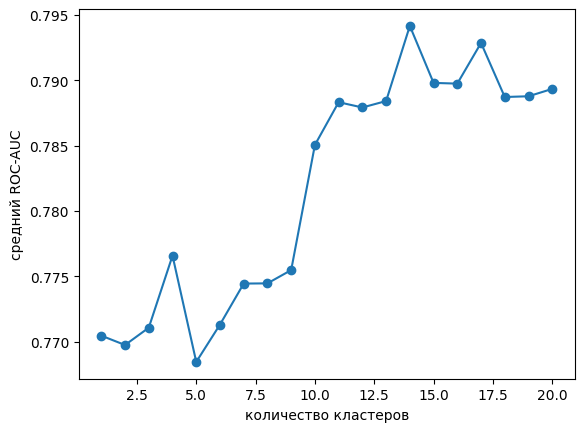

In [27]:
# Средний ROC-AUC логистической регрессии в зависимости от количества кластеров
estimator = LogisticRegression()
ns = range(1, 21)
roc_auc_list = [get_avg_roc_10splits(estimator, create_kmeans_columns(n), y) for n in ns]

fig, ax = plt.subplots()
ax.plot(ns, roc_auc_list, marker='o')
ax.set(xlabel='количество кластеров', ylabel='средний ROC-AUC')
plt.show()